## 拖拉机销售数据预测

1. 数据整理

In [1]:
import pandas as pd

sales_data = pd.read_csv('tractor_sales.csv')
sales_data.head(5)

,Year_Month,Number_of_Sold
0,2003-Jan,141
1,2003-Feb,157
2,2003-Mar,185
3,2003-Apr,199
4,2003-May,203


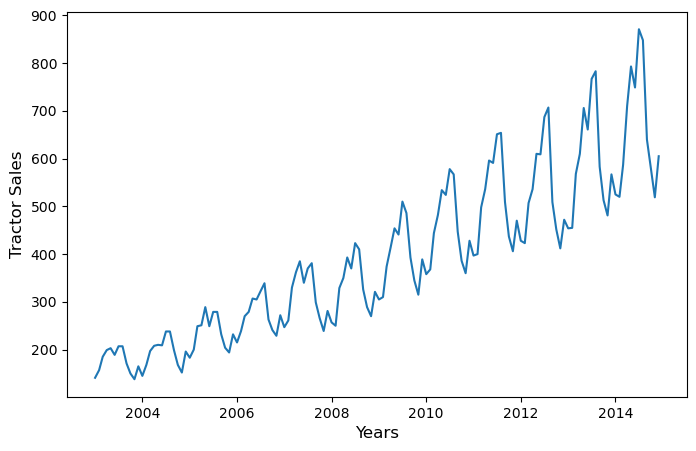

In [2]:
import matplotlib.pyplot as plt
%matplotlib inline

# 将字符串转为日期
dates = pd.to_datetime(sales_data["Year_Month"], format="%Y-%b")

# 设置日期索引
sales_data.set_index(dates, inplace=True)
sales_data.rename(columns={'Number_of_Sold':'Tractor-Sales'}, inplace=True)
sales_ts = sales_data['Tractor-Sales']

# 绘制序列图形
plt.figure(figsize=(8, 5))
plt.plot(sales_ts)
plt.xlabel('Years', fontsize=12)
plt.ylabel('Tractor Sales', fontsize=12)
plt.show()

2.数据探索

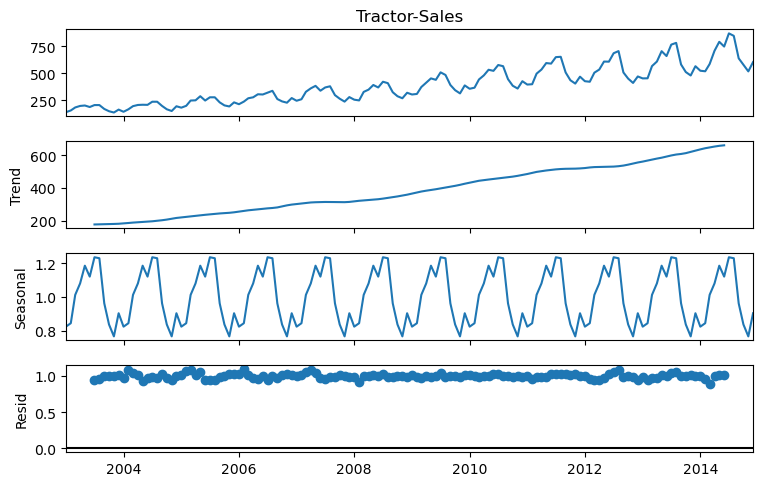

In [3]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

# 趋势分解
decomposition = sm.tsa.seasonal_decompose(sales_ts, model='multiplicative')

# 绘制序列分解后的图形
fig = decomposition.plot()
fig.set_figwidth(8)
fig.set_figheight(5)

plt.show(fig)

In [4]:
# import numpy as np

# #  进行数值转换
# plt.figure(figsize=(10, 5))
# plt.plot(np.log(sales_ts))
# plt.xlabel('Years')
# plt.ylabel('Log (Tractor Sales)')

In [5]:
# #  选择合适的差分阶数

# plt.figure(figsize=(10, 5))
# plt.plot(np.log(sales_ts).diff(periods=1))
# plt.xlabel('Years')
# plt.ylabel('Differenced Log (Tractor Sales)')
# plt.show()

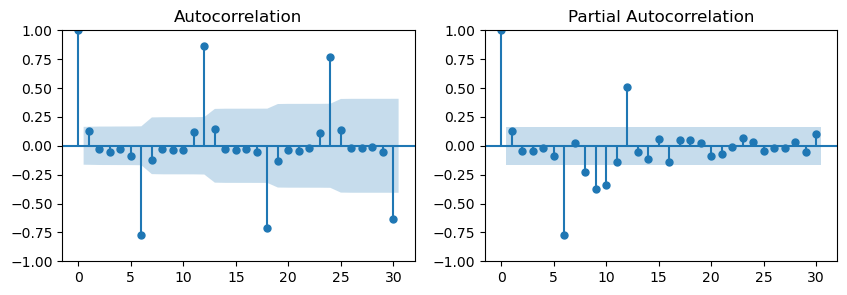

In [6]:
import numpy as np

# 取对数
sales_ts_log = np.log(sales_ts)
sales_ts_log.dropna(inplace=True)

# 一阶差分
sales_ts_log_diff = sales_ts_log.diff(periods=1) 
sales_ts_log_diff.dropna(inplace=True)

# 绘制自相关与偏自相关系数的图形
plt.figure(figsize=(10, 3))
ax1 = plt.subplot(121)
ax2 = plt.subplot(122)
sm.graphics.tsa.plot_acf(sales_ts_log_diff, lags=30, ax=ax1)
sm.graphics.tsa.plot_pacf(sales_ts_log_diff, lags=30, ax=ax2)
plt.show()

3. 确定模型参数

In [7]:
import itertools
import warnings
warnings.filterwarnings("ignore")   # 过滤告警信息

p = d = q = range(0, 2)

# 设置自相关(AR)、差分(I)、移动平均(MA)的三个参数的取值范围
pdq = list(itertools.product(p, d, q))

# 设置季节效应的自相关(AR)、差分(I)、移动平均(MA)的三个参数的取值范围
seasonal_pdq = [(x[0], x[1], x[2], 12) 
                for x in list(itertools.product(p, d, q))]

# 设置初始值
best_aic = np.inf
best_pdq = None
best_seasonal_pdq = None
temp_model = None

# 迭代获得最优参数
for param in pdq:
    for param_seasonal in seasonal_pdq:        
        try:
            temp_model = sm.tsa.statespace.SARIMAX(
                endog=sales_ts_log,
                order=param,
                seasonal_order=param_seasonal,
                enforce_stationarity=True,
                enforce_invertibility=True
            )
            results = temp_model.fit()
            if results.aic < best_aic:
                best_aic = results.aic
                best_pdq = param
                best_seasonal_pdq = param_seasonal
        except:
            continue

# 打印最优参数   
print("Best: SARIMAX{}x{}".format(best_pdq, best_seasonal_pdq))
print("AIC: {}".format(best_aic))

Best: SARIMAX(0, 1, 1)x(1, 0, 1, 12)
AIC: -495.24134026859906


In [8]:
# 用最优参数建模
best_model = sm.tsa.statespace.SARIMAX(
    sales_ts_log,
    order=best_pdq,
    seasonal_order=best_seasonal_pdq,
    enforce_stationarity=True,
    enforce_invertibility=True
)
best_results = best_model.fit()
print(best_results.summary().tables[0])
print(best_results.summary().tables[1])

                                     SARIMAX Results                                      
Dep. Variable:                      Tractor-Sales   No. Observations:                  144
Model:             SARIMAX(0, 1, 1)x(1, 0, 1, 12)   Log Likelihood                 251.621
Date:                            Sun, 04 May 2025   AIC                           -495.241
Time:                                    19:05:09   BIC                           -483.390
Sample:                                01-01-2003   HQIC                          -490.426
                                     - 12-01-2014                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.3575      0.069     -5.195      0.000      -0.492      -0.223
ar.S.L12       0.9933      0.006   

4. 残差诊断

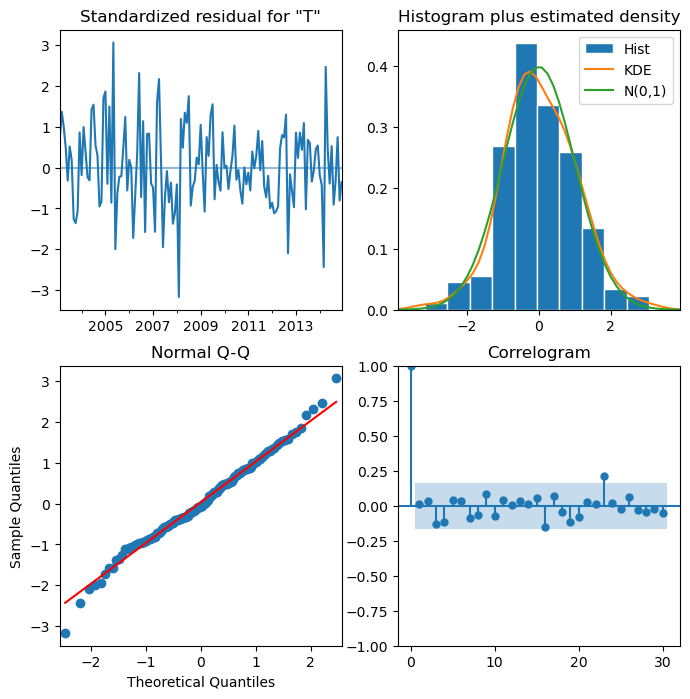

In [9]:
best_results.plot_diagnostics(lags=30, figsize=(8, 8))
plt.show()

5. 预测

In [10]:
n_steps = 36   # 向前预测36期
forecast = best_results.get_forecast(steps=n_steps, alpha=0.05) 
pred_pr_95 = forecast.predicted_mean # 预测的均值
pred_ci_95 = forecast.conf_int()     # 预测的置信区间
idx = pd.date_range(sales_ts.index[-1], periods=n_steps, freq='MS')

fc_95 = pd.DataFrame(
    data=np.column_stack([np.exp(pred_pr_95), np.exp(pred_ci_95)]), 
    index=idx,
    columns=['forecast', 'lower_ci_95', 'upper_ci_95']
)

fc_95.head(5)

,forecast,lower_ci_95,upper_ci_95
2014-12-01,567.463240,528.213426,609.629580
2015-01-01,566.209717,519.968680,616.562989
2015-02-01,668.854575,607.115946,736.871508
2015-03-01,755.211998,678.414957,840.702517
2015-04-01,850.229261,756.570656,955.482201


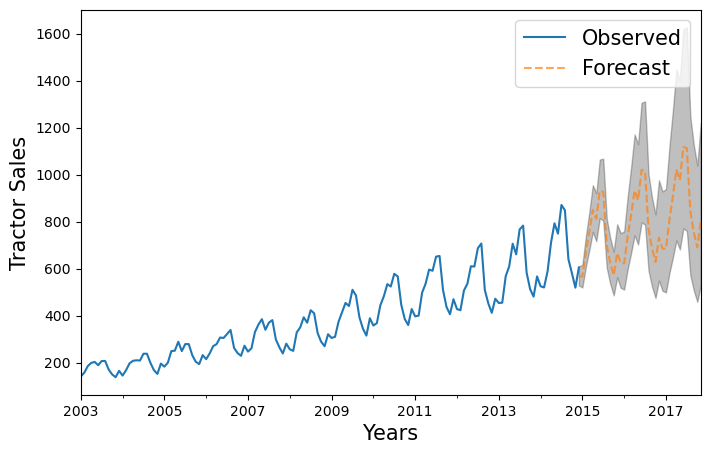

In [11]:
# 绘制观察值
ax = sales_ts.plot(label='Observed', figsize=(8, 5))

# 在同样的轴上绘制预测值
fc_95['forecast'].plot(ax=ax, linestyle='--', label='Forecast', alpha=0.7)

# 绘制置信区间
ax.fill_between(fc_95.index, fc_95['lower_ci_95'], fc_95['upper_ci_95'], 
                  color='k', alpha=.25)

ax.set_xlabel('Years', fontsize=15)
ax.set_ylabel('Tractor Sales', fontsize=15)
plt.legend(loc='best', fontsize=15)
plt.show()